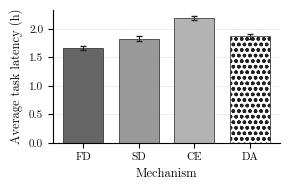

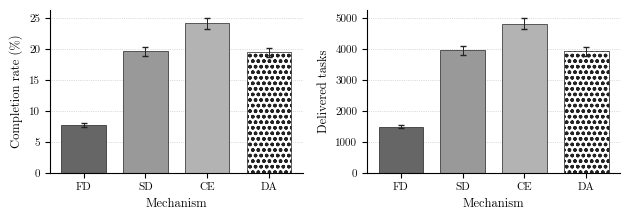

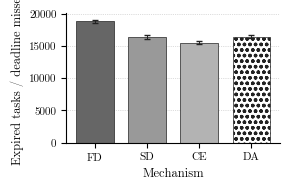

,Mechanism,Average task latency (h),Median latency (min),Completion rate (%),Delivered tasks,Expired/deadline misses,Comp./median latency
0,FD,1.66,18.09,7.66,1489,18852,3.14
1,SD,1.83,8.12,19.59,3961,16413,9.77
2,CE,2.19,11.09,24.12,4826,15557,3.77
3,DA,1.87,8.09,19.43,3929,16449,11.27


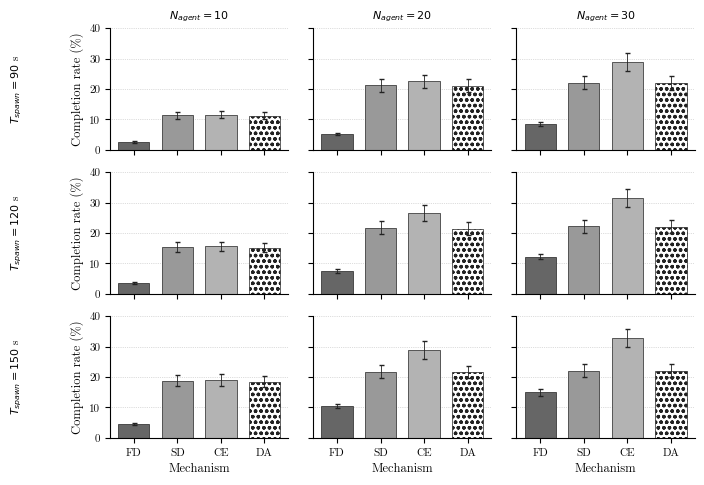

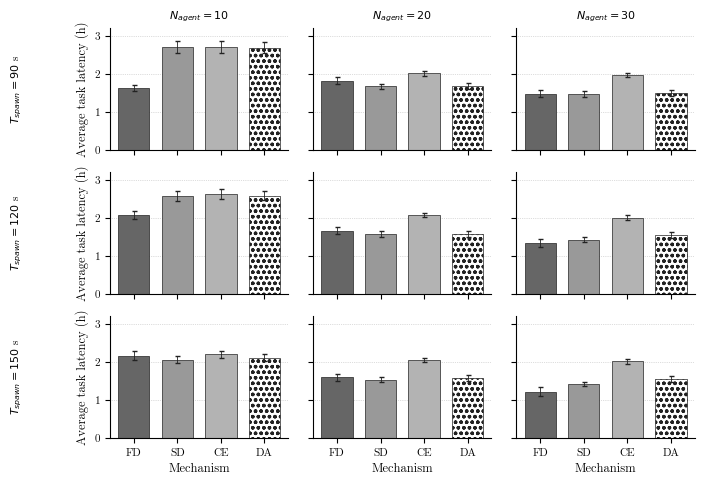

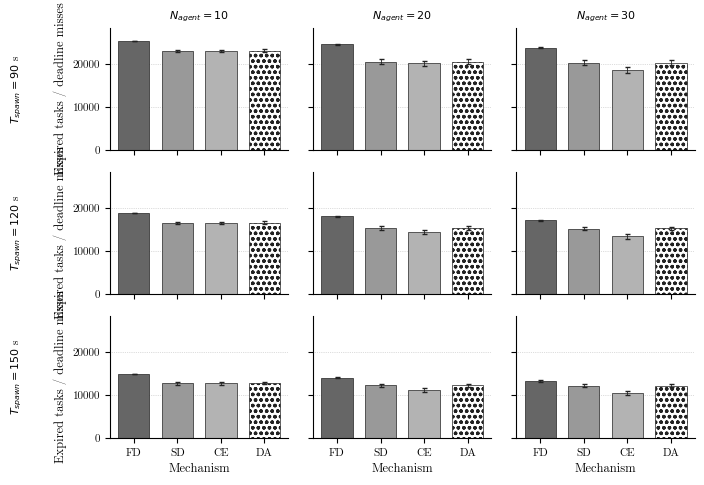

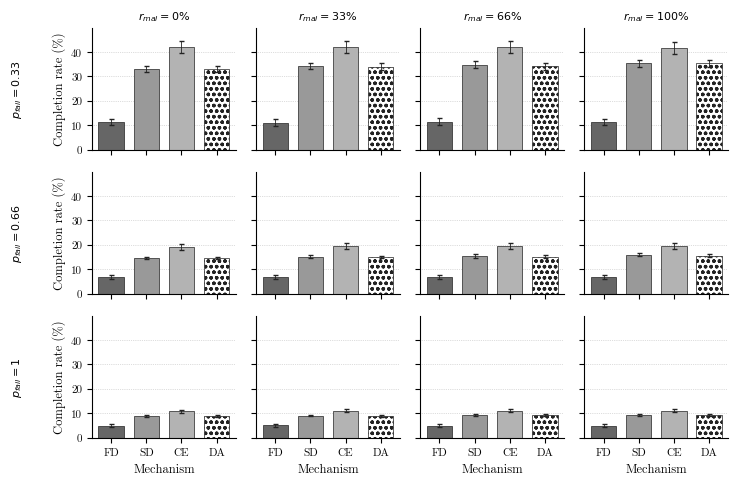

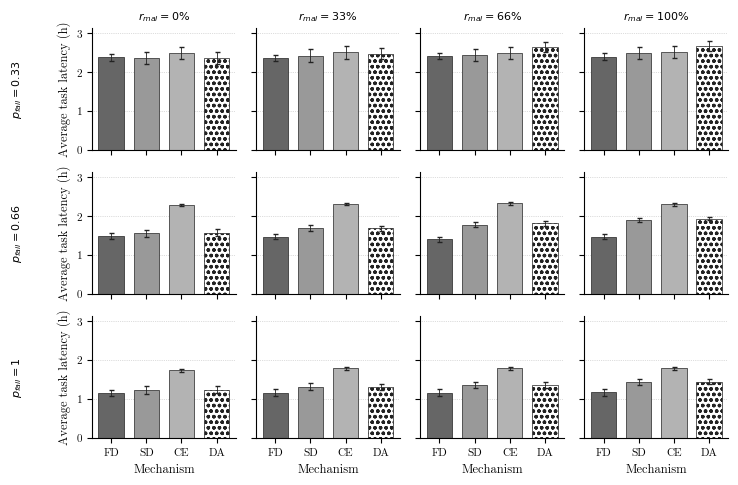

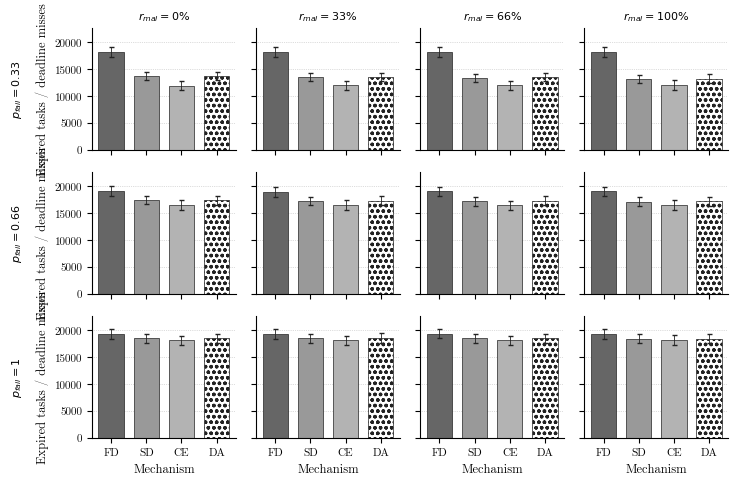

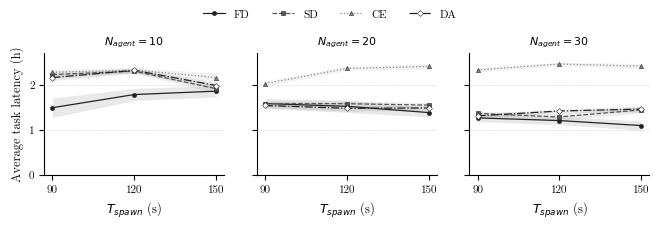

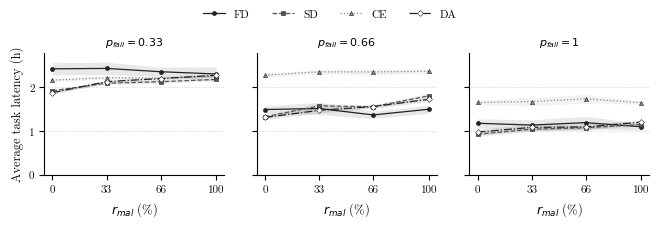

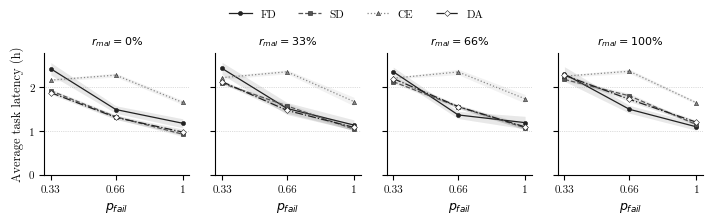

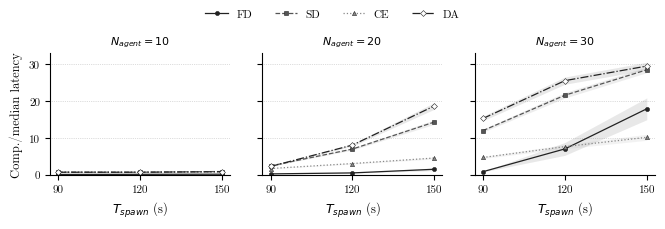

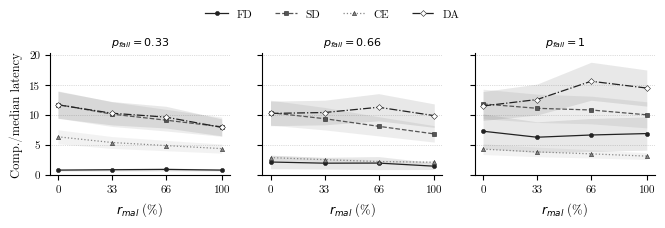

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd

try:
    _IN_IPYTHON = get_ipython() is not None
except NameError:
    _IN_IPYTHON = False

if not _IN_IPYTHON:
    import matplotlib
    matplotlib.use('Agg')

import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    def display(*args, **kwargs):
        return None

RESULTS_ROOT_OVERRIDE = None
SAVE_FIGURES = True
FIGURE_DIR_NAME = 'paper_figures'

plt.rcParams.update({
    'font.family': 'CMU Serif',
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'axes.unicode_minus': False,
})

SINGLE_FIGSIZE = (3.0, 2.0)
WIDE_FIGSIZE = (6.4, 2.3)
TIMELINE_FIGSIZE = (6.8, 3.5)
COORD_ORDER = ['FD', 'SD', 'CE', 'DA']
COORD_COLORS = {'FD': '#666666', 'SD': '#999999', 'CE': '#b3b3b3', 'DA': '#ffffff'}
COORD_HATCHES = {'FD': '', 'SD': '', 'CE': '', 'DA': 'ooo'}
EDGE_COLOR = '#222222'
GRID_COLOR = '#bdbdbd'


def result_root_candidates():
    cwd = Path.cwd()
    candidates = []
    if RESULTS_ROOT_OVERRIDE is not None:
        candidates.append(Path(RESULTS_ROOT_OVERRIDE))
    candidates.extend([
        cwd,
        cwd / 'Paper Results',
        cwd.parent / 'Paper Results',
        Path.home() / 'Desktop' / 'COORDINATE-2.0' / 'Paper Results',
        Path.home() / 'Desktop' / 'Paper Results',
    ])
    unique = []
    for candidate in candidates:
        candidate = candidate.expanduser().resolve()
        if candidate not in unique:
            unique.append(candidate)
    return unique


def find_results_root(required_any=(), required_all=()):
    checked = []
    for root in result_root_candidates():
        checked.append(root)
        if not root.exists():
            continue
        has_any = True if not required_any else any((root / path).exists() for path in required_any)
        has_all = all((root / path).exists() for path in required_all)
        if has_any and has_all:
            return root
    raise FileNotFoundError('Could not find result files. Checked: ' + ', '.join(str(path) for path in checked))


def style_axes(ax, grid_axis='y'):
    ax.set_axisbelow(True)
    if grid_axis:
        ax.grid(axis=grid_axis, linestyle=':', linewidth=0.5, color=GRID_COLOR)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


def coord_color(label):
    return COORD_COLORS.get(str(label), '#b3b3b3')


def coord_hatch(label):
    return COORD_HATCHES.get(str(label), '')


def apply_hatches(bars, labels):
    for bar, label in zip(bars, labels):
        label = str(label)
        bar.set_facecolor(coord_color(label))
        bar.set_edgecolor(EDGE_COLOR)
        bar.set_linewidth(0.5)
        bar.set_hatch(coord_hatch(label))


def save_or_show(fig, root, filename=None):
    if SAVE_FIGURES and filename:
        out_dir = root / FIGURE_DIR_NAME
        out_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(out_dir / filename, bbox_inches='tight')
    if _IN_IPYTHON:
        plt.show()
    else:
        plt.close(fig)



TASK_EXPIRATION_COLUMNS = [
    'expiration_time_low_s',
    'expiration_time_medium_s',
    'expiration_time_high_s',
]


def filter_task_expiration_configured(frame, label, required=True):
    missing = [col for col in TASK_EXPIRATION_COLUMNS if col not in frame.columns]
    if missing:
        if required:
            raise ValueError(f'{label} is missing task-expiration columns: {missing}')
        return frame.copy()
    mask = pd.Series(True, index=frame.index)
    for col in TASK_EXPIRATION_COLUMNS:
        mask &= pd.to_numeric(frame[col], errors='coerce').fillna(0).gt(0)
    filtered = frame.loc[mask].copy()
    if filtered.empty:
        raise ValueError(f'{label} has no rows with task expiration configured.')
    return filtered

def first_existing_column(frame, candidates):
    for column in candidates:
        if column in frame.columns:
            return column
    return None


def numeric(frame, columns):
    for column in columns:
        if column in frame.columns:
            frame[column] = pd.to_numeric(frame[column], errors='coerce')
    return frame


def metric_summary(frame, metric, scale=1.0):
    grouped = frame.groupby('coord_label', observed=False)[metric]
    summary = grouped.agg(['mean', 'std', 'count']).reindex(COORD_ORDER).dropna(subset=['mean']).reset_index()
    summary['mean'] = summary['mean'] * scale
    summary['ci95'] = 1.96 * summary['std'].fillna(0.0) / np.sqrt(summary['count'].clip(lower=1)) * scale
    return summary


def plot_metric_with_ci(frame, metric, ylabel, filename, scale=1.0, title=None):
    summary = metric_summary(frame, metric, scale=scale)
    labels = summary['coord_label'].astype(str).tolist()
    x = np.arange(len(labels))
    fig, ax = plt.subplots(figsize=SINGLE_FIGSIZE)
    bars = ax.bar(x, summary['mean'].to_numpy(), width=0.72)
    apply_hatches(bars, labels)
    ax.errorbar(x, summary['mean'].to_numpy(), yerr=summary['ci95'].to_numpy(), fmt='none',
                ecolor=EDGE_COLOR, elinewidth=0.7, capsize=2)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_xlabel('Mechanism')
    ax.set_ylabel(ylabel)
    if title:
        ax.set_title(title)
    style_axes(ax, grid_axis='y')
    fig.tight_layout()
    save_or_show(fig, ROOT, filename)
    return summary

ROOT = find_results_root(required_all=[Path('RQ1/runs.csv')])
rq1_path = ROOT / 'RQ1' / 'runs.csv'
runs = pd.read_csv(rq1_path)
if 'status' in runs.columns:
    runs = runs[runs['status'].fillna('ok').astype(str).str.lower() == 'ok'].copy()
else:
    runs = runs.copy()
runs = filter_task_expiration_configured(runs, 'RQ1 runs.csv')

metric_columns = [
    'avg_latency_s', 'median_latency_s', 'avg_relative_latency_s', 'relative_latency_s', 'completion_rate',
    'delivered', 'expired', 'deadline_misses', 'throughput_per_hour', 'created', 'pending',
    'switch_count', 'rep', 'event_count', 'wall_time_s',
]
runs = numeric(runs, metric_columns)
runs['completion_latency_efficiency'] = 100 * runs['completion_rate'] / (runs['median_latency_s'] / 60)
runs['coord_label'] = runs['coord_label'].astype(str)
coord_order = [label for label in COORD_ORDER if label in set(runs['coord_label'])]
runs['coord_label'] = pd.Categorical(runs['coord_label'], categories=coord_order, ordered=True)

latency_metric = first_existing_column(runs, ['avg_relative_latency_s', 'relative_latency_s', 'avg_latency_s'])
if latency_metric is None:
    raise ValueError('RQ1 runs.csv does not contain an average latency column.')
latency_label = 'Average relative latency (h)' if 'relative' in latency_metric else 'Average task latency (h)'
latency_summary = plot_metric_with_ci(
    runs,
    latency_metric,
    latency_label,
    'rq1_01_average_task_latency.pdf',
    scale=1 / 3600,
)

completion_summary = metric_summary(runs, 'completion_rate', scale=100)
delivered_summary = metric_summary(runs, 'delivered', scale=1.0)
labels = completion_summary['coord_label'].astype(str).tolist()
x = np.arange(len(labels))
fig, axes = plt.subplots(1, 2, figsize=WIDE_FIGSIZE)
bars = axes[0].bar(x, completion_summary['mean'].to_numpy(), width=0.72)
apply_hatches(bars, labels)
axes[0].errorbar(x, completion_summary['mean'].to_numpy(), yerr=completion_summary['ci95'].to_numpy(),
                 fmt='none', ecolor=EDGE_COLOR, elinewidth=0.7, capsize=2)
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].set_xlabel('Mechanism')
axes[0].set_ylabel('Completion rate (%)')
style_axes(axes[0], grid_axis='y')

bars = axes[1].bar(x, delivered_summary['mean'].to_numpy(), width=0.72)
apply_hatches(bars, labels)
axes[1].errorbar(x, delivered_summary['mean'].to_numpy(), yerr=delivered_summary['ci95'].to_numpy(),
                 fmt='none', ecolor=EDGE_COLOR, elinewidth=0.7, capsize=2)
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_xlabel('Mechanism')
axes[1].set_ylabel('Delivered tasks')
style_axes(axes[1], grid_axis='y')
fig.tight_layout()
save_or_show(fig, ROOT, 'rq1_02_completion_rate_delivered_tasks.pdf')

expired_metric = first_existing_column(runs, ['expired', 'deadline_misses', 'deadline_miss_count', 'missed_deadlines'])
if expired_metric is None:
    raise ValueError('RQ1 runs.csv does not contain expired/deadline-miss information.')
expired_summary = metric_summary(runs, expired_metric, scale=1.0)
labels = expired_summary['coord_label'].astype(str).tolist()
x = np.arange(len(labels))
fig, ax = plt.subplots(figsize=SINGLE_FIGSIZE)
bars = ax.bar(x, expired_summary['mean'].to_numpy(), width=0.72)
apply_hatches(bars, labels)
if expired_summary['mean'].fillna(0).sum() == 0:
    ax.set_ylim(0, 1)
    ax.text(
        0.5, 0.82, 'No expired tasks observed',
        transform=ax.transAxes, ha='center', va='center', fontsize=8,
    )
else:
    ax.errorbar(x, expired_summary['mean'].to_numpy(), yerr=expired_summary['ci95'].to_numpy(),
                fmt='none', ecolor=EDGE_COLOR, elinewidth=0.7, capsize=2)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_xlabel('Mechanism')
ax.set_ylabel('Expired tasks / deadline misses')
style_axes(ax, grid_axis='y')
fig.tight_layout()
save_or_show(fig, ROOT, 'rq1_03_expired_tasks_deadline_misses.pdf')

median_latency_summary = metric_summary(runs, 'median_latency_s', scale=1 / 60)
efficiency_label = 'Comp./median latency'
efficiency_summary = metric_summary(runs, 'completion_latency_efficiency', scale=1.0)

rq1_table = pd.DataFrame({
    'Mechanism': latency_summary['coord_label'].astype(str),
    latency_label: latency_summary['mean'].round(2),
    'Median latency (min)': median_latency_summary['mean'].round(2),
    'Completion rate (%)': completion_summary['mean'].round(2),
    'Delivered tasks': delivered_summary['mean'].round().astype(int),
    'Expired/deadline misses': expired_summary['mean'].round().astype(int),
    efficiency_label: efficiency_summary['mean'].round(2),
})
display(rq1_table)

FACET_GRID_FIGSIZE = (6.8, 5.0)
FACET_GRID_WIDE_FIGSIZE = (7.4, 5.0)


def _as_numeric_label(value):
    number = float(value)
    if number.is_integer():
        return str(int(number))
    return f'{number:g}'


def _metric_summary_for_panel(frame, metric, scale=1.0):
    if frame.empty:
        return pd.DataFrame(columns=['coord_label', 'mean', 'ci95', 'count'])
    grouped = frame.groupby('coord_label', observed=False)[metric]
    summary = grouped.agg(['mean', 'std', 'count']).reindex(COORD_ORDER).dropna(subset=['mean']).reset_index()
    summary['mean'] = summary['mean'] * scale
    summary['ci95'] = 1.96 * summary['std'].fillna(0.0) / np.sqrt(summary['count'].clip(lower=1)) * scale
    return summary


def plot_metric_facets(
    frame,
    *,
    metric,
    ylabel,
    filename,
    row_var,
    col_var,
    row_values,
    col_values,
    row_labeler,
    col_labeler,
    scale=1.0,
    figsize=FACET_GRID_FIGSIZE,
):
    fig, axes = plt.subplots(
        len(row_values), len(col_values),
        figsize=figsize,
        sharey=True,
        squeeze=False,
    )
    max_y = 0.0
    panel_summaries = {}
    for row_value in row_values:
        for col_value in col_values:
            panel = frame[(frame[row_var] == row_value) & (frame[col_var] == col_value)].copy()
            summary = _metric_summary_for_panel(panel, metric, scale=scale)
            panel_summaries[(row_value, col_value)] = summary
            if not summary.empty:
                max_y = max(max_y, (summary['mean'] + summary['ci95']).max())

    for row_idx, row_value in enumerate(row_values):
        for col_idx, col_value in enumerate(col_values):
            ax = axes[row_idx, col_idx]
            summary = panel_summaries[(row_value, col_value)]
            labels = summary['coord_label'].astype(str).tolist() if not summary.empty else []
            x = np.arange(len(labels))
            if labels:
                bars = ax.bar(x, summary['mean'].to_numpy(), width=0.72)
                apply_hatches(bars, labels)
                ax.errorbar(
                    x,
                    summary['mean'].to_numpy(),
                    yerr=summary['ci95'].to_numpy(),
                    fmt='none',
                    ecolor=EDGE_COLOR,
                    elinewidth=0.6,
                    capsize=1.8,
                )
            else:
                ax.text(0.5, 0.5, 'No data', transform=ax.transAxes, ha='center', va='center', fontsize=7)
            ax.set_xticks(x)
            if row_idx == len(row_values) - 1:
                ax.set_xticklabels(labels)
                ax.set_xlabel('Mechanism')
            else:
                ax.set_xticklabels([])
            if col_idx == 0:
                ax.set_ylabel(ylabel)
                ax.text(
                    -0.52, 0.5, row_labeler(row_value),
                    transform=ax.transAxes,
                    rotation=90,
                    ha='center', va='center',
                    fontsize=8,
                )
            if row_idx == 0:
                ax.set_title(col_labeler(col_value), fontsize=8)
            style_axes(ax, grid_axis='y')
            if max_y > 0:
                ax.set_ylim(0, max_y * 1.12)
    fig.subplots_adjust(left=0.13, right=0.99, top=0.92, bottom=0.10, wspace=0.14, hspace=0.18)
    save_or_show(fig, ROOT, filename)


workload_values = sorted(runs['item_spawning_time'].dropna().unique())
agent_values = sorted(runs['n_robots'].dropna().unique())
fault_values = sorted(runs['fail_prob'].dropna().unique())
malicious_values = sorted(runs['malicious_ratio'].dropna().unique())

workload_label = lambda value: f'$T_{{spawn}}={int(value)}$ s'
agent_count_label = lambda value: f'$N_{{agent}}={int(value)}$'
fault_label = lambda value: f'$p_{{fail}}={_as_numeric_label(value)}$'
malicious_label = lambda value: f'$r_{{mal}}={_as_numeric_label(float(value) * 100)}\\%$'

rq1_granular_metrics = [
    ('completion_rate', 'Completion rate (%)', 100.0, 'completion'),
    (latency_metric, latency_label, 1 / 3600, 'latency'),
    (expired_metric, 'Expired tasks / deadline misses', 1.0, 'expired'),
]

workload_agent_files = {
    'completion': 'rq1_06_completion_by_workload_agents.pdf',
    'latency': 'rq1_07_latency_by_workload_agents.pdf',
    'expired': 'rq1_08_expired_by_workload_agents.pdf',
}
fault_malicious_files = {
    'completion': 'rq1_10_completion_by_fault_malicious.pdf',
    'latency': 'rq1_11_latency_by_fault_malicious.pdf',
    'expired': 'rq1_12_expired_by_fault_malicious.pdf',
}

for metric, ylabel, scale, slug in rq1_granular_metrics:
    plot_metric_facets(
        runs,
        metric=metric,
        ylabel=ylabel,
        filename=workload_agent_files[slug],
        row_var='item_spawning_time',
        col_var='n_robots',
        row_values=workload_values,
        col_values=agent_values,
        row_labeler=workload_label,
        col_labeler=agent_count_label,
        scale=scale,
        figsize=FACET_GRID_FIGSIZE,
    )

for metric, ylabel, scale, slug in rq1_granular_metrics:
    plot_metric_facets(
        runs,
        metric=metric,
        ylabel=ylabel,
        filename=fault_malicious_files[slug],
        row_var='fail_prob',
        col_var='malicious_ratio',
        row_values=fault_values,
        col_values=malicious_values,
        row_labeler=fault_label,
        col_labeler=malicious_label,
        scale=scale,
        figsize=FACET_GRID_WIDE_FIGSIZE,
    )

LINE_PANEL_FIGSIZE = (6.8, 2.25)
LINE_PANEL_WIDE_FIGSIZE = (7.4, 2.25)
LINE_STYLE_BY_COORD = {
    'FD': {'color': '#222222', 'linestyle': '-', 'marker': 'o', 'markerfacecolor': '#222222'},
    'SD': {'color': '#555555', 'linestyle': '--', 'marker': 's', 'markerfacecolor': '#555555'},
    'CE': {'color': '#888888', 'linestyle': ':', 'marker': '^', 'markerfacecolor': '#888888'},
    'DA': {'color': '#222222', 'linestyle': '-.', 'marker': 'D', 'markerfacecolor': 'white'},
}
RQ1_NOMINAL = {
    'item_spawning_time': 120,
    'n_robots': 20,
    'fail_prob': 0.66,
    'malicious_ratio': 0.33,
}


def _series_matches_value(series, value):
    if pd.api.types.is_numeric_dtype(series):
        return np.isclose(pd.to_numeric(series, errors='coerce'), float(value))
    return series.astype(str) == str(value)


def _filter_rq1_nominal(frame, filters):
    filtered = frame.copy()
    for column, value in filters.items():
        if column not in filtered.columns:
            continue
        filtered = filtered.loc[_series_matches_value(filtered[column], value)].copy()
    return filtered


def _rq1_line_summary(frame, metric, x_var, panel_var, scale=1.0):
    summary = (
        frame.groupby([panel_var, x_var, 'coord_label'], observed=False)[metric]
        .agg(['mean', 'std', 'count'])
        .reset_index()
    )
    summary['mean'] = summary['mean'] * scale
    summary['ci95'] = 1.96 * summary['std'].fillna(0.0) / np.sqrt(summary['count'].clip(lower=1)) * scale
    return summary


def _line_axis_labels(values, formatter=None):
    if formatter is None:
        return [_as_numeric_label(value) for value in values]
    return [formatter(value) for value in values]


def plot_rq1_line_panels(
    frame,
    *,
    metric,
    ylabel,
    filename,
    x_var,
    panel_var,
    x_values,
    panel_values,
    x_label,
    panel_labeler,
    filters,
    scale=1.0,
    figsize=LINE_PANEL_FIGSIZE,
    x_formatter=None,
):
    plot_frame = _filter_rq1_nominal(frame, filters)
    summary = _rq1_line_summary(plot_frame, metric, x_var, panel_var, scale=scale)
    fig, axes = plt.subplots(1, len(panel_values), figsize=figsize, sharey=True, squeeze=False)
    axes = axes[0]
    y_max = 0.0
    y_min = 0.0
    line_handles = []

    for panel_value in panel_values:
        panel_summary = summary[np.isclose(pd.to_numeric(summary[panel_var], errors='coerce'), float(panel_value))]
        if not panel_summary.empty:
            y_max = max(y_max, (panel_summary['mean'] + panel_summary['ci95']).max())
            y_min = min(y_min, (panel_summary['mean'] - panel_summary['ci95']).min())

    for panel_idx, (ax, panel_value) in enumerate(zip(axes, panel_values)):
        for coord in COORD_ORDER:
            coord_panel = summary[
                np.isclose(pd.to_numeric(summary[panel_var], errors='coerce'), float(panel_value))
                & (summary['coord_label'].astype(str) == coord)
            ].copy()
            if coord_panel.empty:
                continue
            coord_panel = coord_panel.set_index(x_var).reindex(x_values)
            y = coord_panel['mean'].to_numpy(dtype=float)
            ci = coord_panel['ci95'].fillna(0.0).to_numpy(dtype=float)
            x = np.asarray(x_values, dtype=float)
            style = LINE_STYLE_BY_COORD.get(coord, LINE_STYLE_BY_COORD['FD'])
            line, = ax.plot(
                x,
                y,
                color=style['color'],
                linestyle=style['linestyle'],
                linewidth=0.9,
                marker=style['marker'],
                markersize=3.0,
                markerfacecolor=style['markerfacecolor'],
                markeredgecolor=EDGE_COLOR,
                markeredgewidth=0.4,
                label=coord,
            )
            ax.fill_between(
                x,
                y - ci,
                y + ci,
                color=style['color'],
                alpha=0.10,
                linewidth=0,
            )
            if panel_idx == 0:
                line_handles.append(line)
        ax.set_title(panel_labeler(panel_value), fontsize=8)
        ax.set_xlabel(x_label)
        ax.set_xticks(x_values)
        ax.set_xticklabels(_line_axis_labels(x_values, x_formatter))
        if panel_idx == 0:
            ax.set_ylabel(ylabel)
        style_axes(ax, grid_axis='y')
        if y_max > y_min:
            lower = 0 if y_min >= 0 else y_min * 1.08
            ax.set_ylim(lower, y_max * 1.08)
    fig.legend(handles=line_handles, loc='upper center', ncol=len(line_handles), frameon=False)
    fig.subplots_adjust(left=0.10, right=0.99, top=0.78, bottom=0.24, wspace=0.18)
    save_or_show(fig, ROOT, filename)


percent_label = lambda value: f'{_as_numeric_label(float(value) * 100)}'
prob_label = lambda value: _as_numeric_label(value)

plot_rq1_line_panels(
    runs,
    metric=latency_metric,
    ylabel=latency_label,
    filename='rq1_line_latency_vs_workload_by_agents.pdf',
    x_var='item_spawning_time',
    panel_var='n_robots',
    x_values=workload_values,
    panel_values=agent_values,
    x_label='$T_{spawn}$ (s)',
    panel_labeler=agent_count_label,
    filters={
        'fail_prob': RQ1_NOMINAL['fail_prob'],
        'malicious_ratio': RQ1_NOMINAL['malicious_ratio'],
    },
    scale=1 / 3600,
    figsize=LINE_PANEL_FIGSIZE,
)

plot_rq1_line_panels(
    runs,
    metric=latency_metric,
    ylabel=latency_label,
    filename='rq1_line_latency_vs_malicious_by_failure.pdf',
    x_var='malicious_ratio',
    panel_var='fail_prob',
    x_values=malicious_values,
    panel_values=fault_values,
    x_label='$r_{mal}$ (%)',
    panel_labeler=fault_label,
    filters={
        'item_spawning_time': RQ1_NOMINAL['item_spawning_time'],
        'n_robots': RQ1_NOMINAL['n_robots'],
    },
    scale=1 / 3600,
    figsize=LINE_PANEL_FIGSIZE,
    x_formatter=percent_label,
)

plot_rq1_line_panels(
    runs,
    metric=latency_metric,
    ylabel=latency_label,
    filename='rq1_line_latency_vs_failure_by_maliciousness.pdf',
    x_var='fail_prob',
    panel_var='malicious_ratio',
    x_values=fault_values,
    panel_values=malicious_values,
    x_label='$p_{fail}$',
    panel_labeler=malicious_label,
    filters={
        'item_spawning_time': RQ1_NOMINAL['item_spawning_time'],
        'n_robots': RQ1_NOMINAL['n_robots'],
    },
    scale=1 / 3600,
    figsize=LINE_PANEL_WIDE_FIGSIZE,
    x_formatter=prob_label,
)

plot_rq1_line_panels(
    runs,
    metric='completion_latency_efficiency',
    ylabel=efficiency_label,
    filename='rq1_14_efficiency_vs_workload_by_agents.pdf',
    x_var='item_spawning_time',
    panel_var='n_robots',
    x_values=workload_values,
    panel_values=agent_values,
    x_label='$T_{spawn}$ (s)',
    panel_labeler=agent_count_label,
    filters={},
    scale=1.0,
    figsize=LINE_PANEL_FIGSIZE,
)

plot_rq1_line_panels(
    runs,
    metric='completion_latency_efficiency',
    ylabel=efficiency_label,
    filename='rq1_15_efficiency_vs_malicious_by_failure.pdf',
    x_var='malicious_ratio',
    panel_var='fail_prob',
    x_values=malicious_values,
    panel_values=fault_values,
    x_label='$r_{mal}$ (%)',
    panel_labeler=fault_label,
    filters={},
    scale=1.0,
    figsize=LINE_PANEL_FIGSIZE,
    x_formatter=percent_label,
)


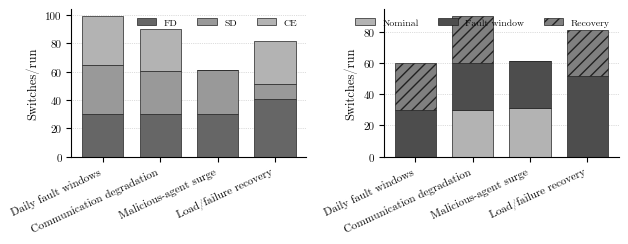

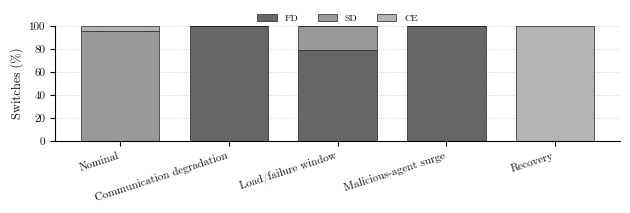

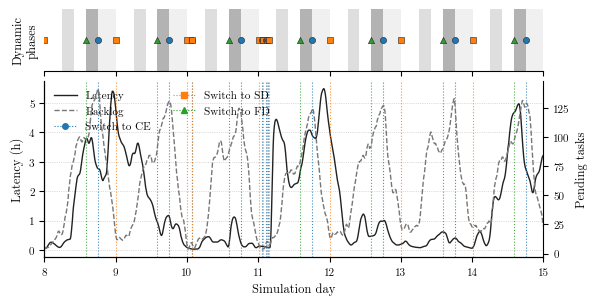

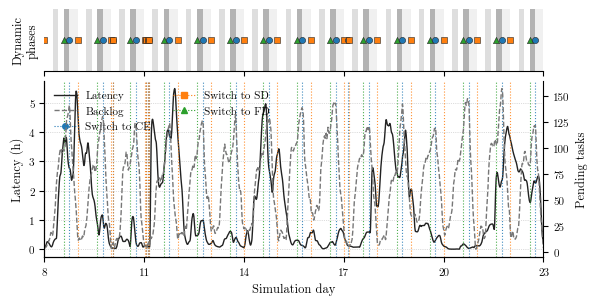

,Profile,Switches/run,First switch (h),Score at switch,FD switches/run,SD switches/run,CE switches/run
0,Daily fault windows,99.2,0.83,0.69,30.1,34.6,34.5
1,Communication degradation,90.2,0.39,0.69,30.1,30.1,30.0
2,Malicious-agent surge,61.2,0.42,0.66,30.1,31.1,0.0
3,Load/failure recovery,81.4,8.16,0.56,40.7,10.5,30.2


,Adaptation context,Switches,Share (%),Selected mech.,Median pending ratio,Median failure rate,Median msg. loss,Median score
0,Recovery mode,900,27.1,CE (100.0%),3.54,1.35,0.000,0.95
1,FD pressure,1310,39.5,FD (100.0%),2.93,1.70,0.106,0.69
2,Stable state,47,1.4,CE (100.0%),0.45,1.05,0.022,0.26
3,Degraded/critical without FD pressure,1063,32.0,SD (100.0%),0.92,1.55,0.000,0.58


In [1]:
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd

try:
    _IN_IPYTHON = get_ipython() is not None
except NameError:
    _IN_IPYTHON = False

if not _IN_IPYTHON:
    import matplotlib
    matplotlib.use('Agg')

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

try:
    from IPython.display import display
except ImportError:
    def display(*args, **kwargs):
        return None

RESULTS_ROOT_OVERRIDE = None
SAVE_FIGURES = True
FIGURE_DIR_NAME = 'paper_figures'

plt.rcParams.update({
    'font.family': 'CMU Serif',
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'axes.unicode_minus': False,
})

SINGLE_FIGSIZE = (3.0, 2.0)
WIDE_FIGSIZE = (6.4, 2.2)
MULTIPANEL_FIGSIZE = (6.4, 4.2)
COORD_ORDER = ['FD', 'SD', 'CE', 'DA']
COORD_COLORS = {'FD': '#666666', 'SD': '#999999', 'CE': '#b3b3b3', 'DA': '#ffffff'}
COORD_HATCHES = {'FD': '', 'SD': '', 'CE': '', 'DA': 'ooo'}
EDGE_COLOR = '#222222'
GRID_COLOR = '#bdbdbd'
LINE_COLORS = ['#222222', '#555555', '#888888', '#b3b3b3', '#d0d0d0']
LINE_STYLES = ['-', '--', ':', '-.']
MARKERS = ['o', 's', '^', 'D', 'v']
SECONDS_PER_DAY = 24 * 3600
TIMELINE_FIGSIZE = (6.4, 3.1)
SWITCH_COLORS = {'CE': '#1f77b4', 'SD': '#ff7f0e', 'FD': '#2ca02c'}
SWITCH_MARKERS = {'CE': 'o', 'SD': 's', 'FD': '^'}


def architecture_to_label(value):
    text = str(value).lower()
    if 'semi' in text:
        return 'SD'
    if 'decentral' in text:
        return 'FD'
    if 'central' in text:
        return 'CE'
    return str(value)



def result_root_candidates():
    cwd = Path.cwd()
    candidates = []
    if RESULTS_ROOT_OVERRIDE is not None:
        candidates.append(Path(RESULTS_ROOT_OVERRIDE))
    candidates.extend([
        cwd,
        cwd / 'Paper Results',
        cwd.parent / 'Paper Results',
        Path.home() / 'Desktop' / 'COORDINATE-2.0' / 'Paper Results',
        Path.home() / 'Desktop' / 'Paper Results',
    ])
    unique = []
    for candidate in candidates:
        candidate = candidate.expanduser().resolve()
        if candidate not in unique:
            unique.append(candidate)
    return unique


def find_results_root(required_any=(), required_all=()):
    checked = []
    for root in result_root_candidates():
        checked.append(root)
        if not root.exists():
            continue
        has_any = True if not required_any else any((root / path).exists() for path in required_any)
        has_all = all((root / path).exists() for path in required_all)
        if has_any and has_all:
            return root
    raise FileNotFoundError('Could not find result files. Checked: ' + ', '.join(str(path) for path in checked))


def style_axes(ax, grid_axis='y'):
    ax.set_axisbelow(True)
    if grid_axis:
        ax.grid(axis=grid_axis, linestyle=':', linewidth=0.5, color=GRID_COLOR)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


def coord_color(label):
    return COORD_COLORS.get(str(label), '#b3b3b3')


def coord_hatch(label):
    return COORD_HATCHES.get(str(label), '')


def apply_hatches(bars, labels):
    for bar, label in zip(bars, labels):
        label = str(label)
        bar.set_facecolor(coord_color(label))
        bar.set_edgecolor(EDGE_COLOR)
        bar.set_linewidth(0.5)
        bar.set_hatch(coord_hatch(label))


def plot_coord_bars(ax, labels, values, width=0.72):
    labels = [str(label) for label in labels]
    x = np.arange(len(labels))
    bars = ax.bar(x, values, width=width)
    apply_hatches(bars, labels)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    style_axes(ax, grid_axis='y')
    return bars


def style_pandas_bar_containers(ax, labels):
    for container, label in zip(ax.containers, labels):
        for patch in container.patches:
            patch.set_facecolor(coord_color(label))
            patch.set_edgecolor(EDGE_COLOR)
            patch.set_linewidth(0.5)
            patch.set_hatch(coord_hatch(label))
    style_axes(ax, grid_axis='y')


def save_or_show(fig, root, filename=None):
    if SAVE_FIGURES and filename:
        out_dir = root / FIGURE_DIR_NAME
        out_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(out_dir / filename, bbox_inches='tight')
    if _IN_IPYTHON:
        plt.show()
    else:
        plt.close(fig)


TASK_EXPIRATION_COLUMNS = [
    'expiration_time_low_s',
    'expiration_time_medium_s',
    'expiration_time_high_s',
]


def filter_task_expiration_configured(frame, label, required=True):
    missing = [col for col in TASK_EXPIRATION_COLUMNS if col not in frame.columns]
    if missing:
        if required:
            raise ValueError(f'{label} is missing task-expiration columns: {missing}')
        return frame.copy()
    mask = pd.Series(True, index=frame.index)
    for col in TASK_EXPIRATION_COLUMNS:
        mask &= pd.to_numeric(frame[col], errors='coerce').fillna(0).gt(0)
    filtered = frame.loc[mask].copy()
    if filtered.empty:
        raise ValueError(f'{label} has no rows with task expiration configured.')
    return filtered

ROOT = find_results_root(required_all=[Path('RQ2/runs.csv'), Path('RQ2/switch_timeline.csv')])
rq2 = ROOT / 'RQ2'
runs = pd.read_csv(rq2 / 'runs.csv')
switches = pd.read_csv(rq2 / 'switch_timeline.csv')

if 'status' in runs.columns:
    runs = runs[runs['status'].fillna('ok').astype(str).str.lower() == 'ok'].copy()
else:
    runs = runs.copy()
runs = filter_task_expiration_configured(runs, 'RQ2 runs.csv')
switches = filter_task_expiration_configured(switches, 'RQ2 switch_timeline.csv', required=False)
if 'run_id' in switches.columns and 'run_id' in runs.columns:
    switches = switches[switches['run_id'].astype(str).isin(set(runs['run_id'].astype(str)))].copy()

def numeric(frame, columns):
    for column in columns:
        if column in frame.columns:
            frame[column] = pd.to_numeric(frame[column], errors='coerce')
    return frame


for frame in [runs, switches]:
    numeric(frame, [
        'rep', 'switch_count', 'fd_switch_count', 'sd_switch_count', 'ce_switch_count',
        'first_switch_time', 'performance_score', 'latency', 'pending_ratio',
        'failure_rate', 'message_loss_rate', 'switch_idx', 'sim_time', 'sim_day', 'sim_hour',
    ])

profile_order = ['paper_daily_stress', 'communication_blackout', 'malicious_surge', 'load_fault_recovery']
profile_labels = {
    'paper_daily_stress': 'Daily fault windows',
    'communication_blackout': 'Communication degradation',
    'malicious_surge': 'Malicious-agent surge',
    'load_fault_recovery': 'Load/failure recovery',
}
phase_groups = {
    'normal': 'Nominal',
    'calm': 'Nominal',
    'paper_stress': 'Fault window',
    'comm_blackout': 'Fault window',
    'malicious_surge': 'Fault window',
    'load_fault_stress': 'Fault window',
    'recovery': 'Recovery',
}
mechanism_order = ['FD', 'SD', 'CE']
phase_order = ['Nominal', 'Fault window', 'Recovery']
phase_colors = {'Nominal': '#b3b3b3', 'Fault window': '#4d4d4d', 'Recovery': '#808080'}
phase_hatches = {'Nominal': '', 'Fault window': '', 'Recovery': '///'}

runs = runs[runs['profile'].isin(profile_order)].copy()
switches = switches[switches['profile'].isin(profile_order)].copy()
runs['profile'] = pd.Categorical(runs['profile'], categories=profile_order, ordered=True)
switches['profile'] = pd.Categorical(switches['profile'], categories=profile_order, ordered=True)

run_counts = runs.groupby('profile', observed=False)['run_id'].nunique().reindex(profile_order).replace(0, np.nan)
mech_counts = switches.pivot_table(
    index='profile', columns='selected_coord_label', values='switch_idx', aggfunc='count', fill_value=0, observed=False,
).reindex(index=profile_order, columns=mechanism_order, fill_value=0)
mech_per_run = mech_counts.div(run_counts, axis=0)

switches['phase_group'] = switches['phase_label'].map(phase_groups).fillna('Other')
phase_counts = switches.pivot_table(
    index='profile', columns='phase_group', values='switch_idx', aggfunc='count', fill_value=0, observed=False,
).reindex(index=profile_order, columns=phase_order, fill_value=0)
phase_per_run = phase_counts.div(run_counts, axis=0)

profile_summary = runs.groupby('profile', observed=False).agg(
    switches_per_run=('switch_count', 'mean'),
    first_switch_h=('first_switch_time', lambda values: values.mean() / 3600),
).reindex(profile_order)
score_at_switch = switches.groupby('profile', observed=False)['performance_score'].mean().reindex(profile_order)

rq2_table = pd.DataFrame({
    'Profile': [profile_labels[p] for p in profile_order],
    'Switches/run': profile_summary['switches_per_run'].round(1).to_numpy(),
    'First switch (h)': profile_summary['first_switch_h'].round(2).to_numpy(),
    'Score at switch': score_at_switch.round(2).to_numpy(),
    'FD switches/run': mech_per_run['FD'].round(1).to_numpy(),
    'SD switches/run': mech_per_run['SD'].round(1).to_numpy(),
    'CE switches/run': mech_per_run['CE'].round(1).to_numpy(),
})

fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.55))
x = np.arange(len(profile_order))
labels = [profile_labels[p] for p in profile_order]

bottom = np.zeros(len(profile_order))
for mechanism in mechanism_order:
    values = mech_per_run[mechanism].fillna(0).to_numpy()
    bars = axes[0].bar(x, values, bottom=bottom, width=0.72, label=mechanism)
    apply_hatches(bars, [mechanism] * len(values))
    bottom += values
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels, rotation=25, ha='right')
axes[0].set_ylabel('Switches/run')
style_axes(axes[0], grid_axis='y')
axes[0].legend(frameon=False, fontsize=7, ncol=3)

bottom = np.zeros(len(profile_order))
for phase in phase_order:
    values = phase_per_run[phase].fillna(0).to_numpy()
    bars = axes[1].bar(x, values, bottom=bottom, width=0.72, label=phase)
    for bar in bars:
        bar.set_facecolor(phase_colors[phase])
        bar.set_edgecolor(EDGE_COLOR)
        bar.set_linewidth(0.5)
        bar.set_hatch(phase_hatches[phase])
    bottom += values
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels, rotation=25, ha='right')
axes[1].set_ylabel('Switches/run')
style_axes(axes[1], grid_axis='y')
axes[1].legend(frameon=False, fontsize=7, ncol=3)

fig.tight_layout()
save_or_show(fig, ROOT, 'rq2_dynamic_reaction.pdf')

phase_detail_groups = {
    'normal': 'Nominal',
    'nominal': 'Nominal',
    'baseline': 'Nominal',
    'calm': 'Nominal',
    'comm_blackout': 'Communication degradation',
    'load_fault_stress': 'Load/failure window',
    'load_failure_surge': 'Load/failure window',
    'malicious_surge': 'Malicious-agent surge',
    'recovery': 'Recovery',
}
phase_detail_order = ['Nominal', 'Communication degradation', 'Load/failure window', 'Malicious-agent surge', 'Recovery']
switches['phase_detail'] = switches['phase_label'].map(phase_detail_groups).fillna(switches['phase_label'].astype(str))
phase_selection = pd.crosstab(switches['phase_detail'], switches['selected_coord_label']).reindex(
    index=phase_detail_order, columns=mechanism_order, fill_value=0,
)
phase_selection_pct = phase_selection.div(phase_selection.sum(axis=1).replace(0, np.nan), axis=0) * 100

fig, ax = plt.subplots(figsize=(6.4, 2.35))
x = np.arange(len(phase_detail_order))
bottom = np.zeros(len(phase_detail_order))
for mechanism in mechanism_order:
    values = phase_selection_pct[mechanism].fillna(0).to_numpy()
    bars = ax.bar(x, values, bottom=bottom, width=0.72, label=mechanism)
    apply_hatches(bars, [mechanism] * len(values))
    bottom += values
ax.set_xticks(x)
ax.set_xticklabels(phase_detail_order, rotation=18, ha='right')
ax.set_ylabel('Switches (%)')
ax.set_ylim(0, 100)
style_axes(ax, grid_axis='y')
ax.legend(frameon=False, fontsize=7, ncol=3, loc='upper center', bbox_to_anchor=(0.5, 1.18))
fig.tight_layout()
save_or_show(fig, ROOT, 'rq2_switch_selection_by_phase.pdf')

recovery_mask = switches['recovery_mode'].astype(str).str.lower().eq('true')
fd_pressure_mask = switches['fd_pressure'].astype(str).str.lower().eq('true')
state_series = switches['performance_state'].astype(str)
context_specs = [
    ('Recovery mode', recovery_mask),
    ('FD pressure', (~recovery_mask) & fd_pressure_mask),
    ('Stable state', (~recovery_mask) & (~fd_pressure_mask) & state_series.eq('stable')),
    ('Degraded/critical without FD pressure', (~recovery_mask) & (~fd_pressure_mask) & (~state_series.eq('stable'))),
]
context_rows = []
for context_label, mask in context_specs:
    group = switches.loc[mask].copy()
    if group.empty:
        continue
    selected_counts = group['selected_coord_label'].value_counts()
    dominant_mechanism = selected_counts.idxmax()
    dominant_share = 100 * selected_counts.max() / len(group)
    context_rows.append({
        'Adaptation context': context_label,
        'Switches': int(len(group)),
        'Share (%)': round(100 * len(group) / max(1, len(switches)), 1),
        'Selected mech.': f'{dominant_mechanism} ({dominant_share:.1f}%)',
        'Median pending ratio': round(group['pending_ratio'].median(), 2),
        'Median failure rate': round(group['failure_rate'].median(), 2),
        'Median msg. loss': round(group['message_loss_rate'].median(), 3),
        'Median score': round(group['performance_score'].median(), 2),
    })
rq2_context_table = pd.DataFrame(context_rows)

timeline_path = rq2 / 'adaptation_state_timeseries.csv.gz'
phase_path = rq2 / 'phase_schedule.csv'
if timeline_path.exists() and phase_path.exists():
    timeline = pd.read_csv(timeline_path)
    phases = pd.read_csv(phase_path)
    timeline = filter_task_expiration_configured(timeline, 'RQ2 adaptation_state_timeseries.csv.gz', required=False)
    if 'run_id' in phases.columns and 'run_id' in timeline.columns:
        phases = phases[phases['run_id'].astype(str).isin(set(timeline['run_id'].astype(str)))].copy()
    timeline = numeric(timeline, [
        'sim_time', 'latency', 'raw_latency', 'pending_tasks', 'sim_day',
        'phase_fail_prob', 'phase_msg_loss', 'phase_n_malicious',
    ])
    phases = numeric(phases, ['start', 'end', 'FAIL_PROB', 'COMM_FAIL_PROB', 'N_MALICIOUS'])

    candidate_runs = timeline.copy()
    if 'profile' in candidate_runs.columns:
        preferred = candidate_runs[candidate_runs['profile'].astype(str) == 'paper_daily_stress']
        if not preferred.empty:
            candidate_runs = preferred
    switched_flag = candidate_runs['switched'].astype(str).str.lower().eq('true')
    switch_counts = candidate_runs.assign(_switched=switched_flag).groupby('run_id')['_switched'].sum()
    selected_run = switch_counts.sort_values(ascending=False).index[0]

    trace_all = timeline[timeline['run_id'] == selected_run].copy().sort_values('sim_time')
    phase_trace_all = phases[phases['run_id'] == selected_run].copy().sort_values('start')
    latency_column = 'latency' if trace_all['latency'].notna().any() else 'raw_latency'

    phase_shades = {
        'load_failure_surge': '#d9d9d9',
        'load_fault_stress': '#d9d9d9',
        'comm_blackout': '#bdbdbd',
        'malicious_surge': '#a6a6a6',
        'recovery': '#eeeeee',
    }

    def plot_da_timeline_window(start_day, window_days, filename):
        start_time = (start_day - 1) * SECONDS_PER_DAY
        end_time = start_time + window_days * SECONDS_PER_DAY
        trace = trace_all[(trace_all['sim_time'] >= start_time) & (trace_all['sim_time'] <= end_time)].copy()
        phase_trace = phase_trace_all[(phase_trace_all['end'] >= start_time) & (phase_trace_all['start'] <= end_time)].copy()
        if trace.empty:
            return
        phase_trace['plot_start'] = phase_trace['start'].clip(lower=start_time, upper=end_time) / SECONDS_PER_DAY + 1
        phase_trace['plot_end'] = phase_trace['end'].clip(lower=start_time, upper=end_time) / SECONDS_PER_DAY + 1
        trace['latency_h'] = trace[latency_column].rolling(window=5, min_periods=1).mean() / 3600
        trace['pending_smooth'] = trace['pending_tasks'].rolling(window=5, min_periods=1).mean()
        trace['sim_day_axis'] = trace['sim_time'] / SECONDS_PER_DAY + 1

        fig, (ax_windows, ax_perf) = plt.subplots(
            2, 1, figsize=TIMELINE_FIGSIZE, sharex=True,
            gridspec_kw={'height_ratios': [0.35, 1.0], 'hspace': 0.08},
        )

        for _, phase in phase_trace.iterrows():
            label = str(phase.get('phase_label', '')).lower()
            shade = phase_shades.get(label)
            if shade:
                ax_windows.axvspan(
                    phase['plot_start'], phase['plot_end'],
                    color=shade, alpha=0.85, linewidth=0,
                )
        ax_windows.set_ylim(0, 1)
        ax_windows.set_yticks([])
        ax_windows.set_ylabel('Dynamic\nphases')
        ax_windows.spines['top'].set_visible(False)
        ax_windows.spines['right'].set_visible(False)
        ax_windows.spines['left'].set_visible(False)

        ax_perf.plot(trace['sim_day_axis'], trace['latency_h'], color='#222222', linewidth=1.0,
                     label='Latency')
        ax_perf.set_ylabel('Latency (h)')
        style_axes(ax_perf, grid_axis='y')

        ax_backlog = ax_perf.twinx()
        ax_backlog.plot(trace['sim_day_axis'], trace['pending_smooth'], color='#777777', linewidth=1.0,
                        linestyle='--', label='Backlog')
        ax_backlog.set_ylabel('Pending tasks')
        ax_backlog.spines['top'].set_visible(False)

        switch_trace = trace[trace['switched'].astype(str).str.lower().eq('true')].copy()
        seen_switch_labels = set()
        for _, switch in switch_trace.iterrows():
            selected = architecture_to_label(switch.get('selected_architecture', ''))
            x_value = switch['sim_day_axis']
            ax_perf.axvline(x_value, color=SWITCH_COLORS.get(selected, '#444444'),
                            linestyle=':', linewidth=0.8, alpha=0.85)
            ax_windows.scatter(
                [x_value], [0.5], s=20, marker=SWITCH_MARKERS.get(selected, 'o'),
                facecolor=SWITCH_COLORS.get(selected, '#444444'), edgecolor=EDGE_COLOR,
                linewidth=0.4, zorder=3,
            )
            seen_switch_labels.add(selected)

        line_handles = [
            Line2D([0], [0], color='#222222', lw=1.0, label='Latency'),
            Line2D([0], [0], color='#777777', lw=1.0, linestyle='--', label='Backlog'),
        ]
        switch_handles = [
            Line2D([0], [0], color=SWITCH_COLORS[label], marker=SWITCH_MARKERS[label],
                   linestyle=':', lw=0.8, markersize=4, label=f'Switch to {label}')
            for label in ['CE', 'SD', 'FD'] if label in seen_switch_labels
        ]
        ax_perf.legend(handles=line_handles + switch_handles, loc='upper left', ncol=2, frameon=False)
        ax_perf.set_xlabel('Simulation day')
        x_min = start_time / SECONDS_PER_DAY + 1
        x_max = end_time / SECONDS_PER_DAY + 1
        ax_perf.set_xlim(x_min, x_max)
        tick_step = 1 if window_days <= 7 else 3
        ax_perf.set_xticks(np.arange(x_min, x_max + 0.1, tick_step))
        fig.subplots_adjust(left=0.10, right=0.88, top=0.96, bottom=0.16, hspace=0.08)
        save_or_show(fig, ROOT, filename)

    plot_da_timeline_window(8, 7, 'rq2_da_intermediate_timeline_7d.pdf')
    plot_da_timeline_window(8, 15, 'rq2_da_intermediate_timeline_15d.pdf')

display(rq2_table)
display(rq2_context_table)

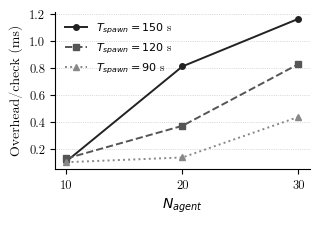

,Mechanism,Simulation wall time (s),Events (avg),Trace size (MB),Adapt. checks (avg),Overhead/check (ms),Overhead share (%)
0,CE,9.61,102732,3.56,-,-,-
3,SD,8.5,99837,3.47,-,-,-
2,FD,6.47,71987,2.6,-,-,-
1,DA,12.32,99869,5.49,4065,0.46,13.87


In [3]:
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd

try:
    _IN_IPYTHON = get_ipython() is not None
except NameError:
    _IN_IPYTHON = False

if not _IN_IPYTHON:
    import matplotlib
    matplotlib.use('Agg')

import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    def display(*args, **kwargs):
        return None

RESULTS_ROOT_OVERRIDE = None
SAVE_FIGURES = True
FIGURE_DIR_NAME = 'paper_figures'

plt.rcParams.update({
    'font.family': 'CMU Serif',
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'axes.unicode_minus': False,
})

SINGLE_FIGSIZE = (3.0, 2.0)
WIDE_FIGSIZE = (6.4, 2.2)
MULTIPANEL_FIGSIZE = (6.4, 4.2)
COORD_ORDER = ['FD', 'SD', 'CE', 'DA']
COORD_COLORS = {'FD': '#666666', 'SD': '#999999', 'CE': '#b3b3b3', 'DA': '#ffffff'}
COORD_HATCHES = {'FD': '', 'SD': '', 'CE': '', 'DA': 'ooo'}
EDGE_COLOR = '#222222'
GRID_COLOR = '#bdbdbd'
LINE_COLORS = ['#222222', '#555555', '#888888', '#b3b3b3', '#d0d0d0']
LINE_STYLES = ['-', '--', ':', '-.']
MARKERS = ['o', 's', '^', 'D', 'v']


def result_root_candidates():
    cwd = Path.cwd()
    candidates = []
    if RESULTS_ROOT_OVERRIDE is not None:
        candidates.append(Path(RESULTS_ROOT_OVERRIDE))
    candidates.extend([
        cwd,
        cwd / 'Paper Results',
        cwd.parent / 'Paper Results',
        Path.home() / 'Desktop' / 'COORDINATE-2.0' / 'Paper Results',
        Path.home() / 'Desktop' / 'Paper Results',
    ])
    unique = []
    for candidate in candidates:
        candidate = candidate.expanduser().resolve()
        if candidate not in unique:
            unique.append(candidate)
    return unique


def find_results_root(required_any=(), required_all=()):
    checked = []
    for root in result_root_candidates():
        checked.append(root)
        if not root.exists():
            continue
        has_any = True if not required_any else any((root / path).exists() for path in required_any)
        has_all = all((root / path).exists() for path in required_all)
        if has_any and has_all:
            return root
    raise FileNotFoundError('Could not find result files. Checked: ' + ', '.join(str(path) for path in checked))


def style_axes(ax, grid_axis='y'):
    ax.set_axisbelow(True)
    if grid_axis:
        ax.grid(axis=grid_axis, linestyle=':', linewidth=0.5, color=GRID_COLOR)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


def coord_color(label):
    return COORD_COLORS.get(str(label), '#b3b3b3')


def coord_hatch(label):
    return COORD_HATCHES.get(str(label), '')


def apply_hatches(bars, labels):
    for bar, label in zip(bars, labels):
        label = str(label)
        bar.set_facecolor(coord_color(label))
        bar.set_edgecolor(EDGE_COLOR)
        bar.set_linewidth(0.5)
        bar.set_hatch(coord_hatch(label))


def plot_coord_bars(ax, labels, values, width=0.72):
    labels = [str(label) for label in labels]
    x = np.arange(len(labels))
    bars = ax.bar(x, values, width=width)
    apply_hatches(bars, labels)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    style_axes(ax, grid_axis='y')
    return bars


def style_pandas_bar_containers(ax, labels):
    for container, label in zip(ax.containers, labels):
        for patch in container.patches:
            patch.set_facecolor(coord_color(label))
            patch.set_edgecolor(EDGE_COLOR)
            patch.set_linewidth(0.5)
            patch.set_hatch(coord_hatch(label))
    style_axes(ax, grid_axis='y')


def save_or_show(fig, root, filename=None):
    if SAVE_FIGURES and filename:
        out_dir = root / FIGURE_DIR_NAME
        out_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(out_dir / filename, bbox_inches='tight')
    if _IN_IPYTHON:
        plt.show()
    else:
        plt.close(fig)

ROOT = find_results_root(required_all=[Path('RQ3/runs.csv')])
rq3 = ROOT / 'RQ3'
runs_path = rq3 / 'runs.csv'

runs = pd.read_csv(runs_path)
if 'status' in runs.columns:
    runs = runs[runs['status'].fillna('ok') == 'ok'].copy()
else:
    runs = runs.copy()

numeric_cols = [
    'rep', 'item_spawning_time', 'n_robots', 'wall_time_s', 'event_count',
    'events_per_wall_s', 'adapt_checks', 'adapt_overhead_ms_total',
    'adapt_overhead_ms_mean', 'adapt_overhead_ms_p95', 'rtlola_query_ms_mean',
    'scoring_ms_mean', 'adapt_overhead_wall_pct', 'trace_size_mb',
    'overhead_trace_size_mb',
]
for col in numeric_cols:
    if col in runs.columns:
        runs[col] = pd.to_numeric(runs[col], errors='coerce')

runs['coord_label'] = runs['coord_label'].astype(str).str.upper().str.strip()
coord_order = ['CE', 'SD', 'FD', 'DA']
runs = runs[runs['coord_label'].isin(coord_order)].copy()
runs['total_trace_size_mb'] = runs['trace_size_mb'].fillna(0) + runs['overhead_trace_size_mb'].fillna(0)

mechanism_summary = (
    runs.groupby(['coord_label', 'architecture'], as_index=False)
    .agg(
        runs=('run_id', 'count'),
        wall_time_s=('wall_time_s', 'mean'),
        wall_time_s_p95=('wall_time_s', lambda values: values.quantile(0.95)),
        event_count=('event_count', 'mean'),
        total_trace_size_mb=('total_trace_size_mb', 'mean'),
        adapt_checks=('adapt_checks', 'mean'),
        adapt_overhead_ms_mean=('adapt_overhead_ms_mean', 'mean'),
        adapt_overhead_ms_p95=('adapt_overhead_ms_p95', 'mean'),
        rtlola_query_ms_mean=('rtlola_query_ms_mean', 'mean'),
        scoring_ms_mean=('scoring_ms_mean', 'mean'),
        adapt_overhead_wall_pct=('adapt_overhead_wall_pct', 'mean'),
    )
)
mechanism_summary['coord_label'] = pd.Categorical(mechanism_summary['coord_label'], categories=coord_order, ordered=True)
mechanism_summary = mechanism_summary.sort_values('coord_label')

rq3_table = mechanism_summary[[
    'coord_label', 'wall_time_s', 'event_count', 'total_trace_size_mb',
    'adapt_checks', 'adapt_overhead_ms_mean', 'adapt_overhead_wall_pct',
]].rename(columns={
    'coord_label': 'Mechanism',
    'wall_time_s': 'Simulation wall time (s)',
    'event_count': 'Events (avg)',
    'total_trace_size_mb': 'Trace size (MB)',
    'adapt_checks': 'Adapt. checks (avg)',
    'adapt_overhead_ms_mean': 'Overhead/check (ms)',
    'adapt_overhead_wall_pct': 'Overhead share (%)',
})
rq3_table['Simulation wall time (s)'] = rq3_table['Simulation wall time (s)'].round(2)
rq3_table['Events (avg)'] = rq3_table['Events (avg)'].round(0).astype('Int64')
rq3_table['Trace size (MB)'] = rq3_table['Trace size (MB)'].round(2)
rq3_table['Adapt. checks (avg)'] = rq3_table['Adapt. checks (avg)'].round(0).astype('Int64')
rq3_table['Overhead/check (ms)'] = rq3_table['Overhead/check (ms)'].round(2)
rq3_table['Overhead share (%)'] = rq3_table['Overhead share (%)'].round(2)
static_mask = rq3_table['Mechanism'] != 'DA'
rq3_table.loc[static_mask, ['Adapt. checks (avg)', 'Overhead/check (ms)', 'Overhead share (%)']] = pd.NA
rq3_table = rq3_table.astype(object).where(pd.notna(rq3_table), '-')

fig, ax = plt.subplots(1, 1, figsize=(3.3, 2.35))
da = runs[runs['coord_label'] == 'DA'].copy()
if not da.empty:
    overhead = (
        da.groupby(['item_spawning_time', 'n_robots'], as_index=False)
        .agg(overhead_ms=('adapt_overhead_ms_mean', 'mean'))
    )
    spawn_order = [value for value in [150, 120, 90] if value in set(overhead['item_spawning_time'])]
    for idx, spawn in enumerate(spawn_order):
        frame = overhead[overhead['item_spawning_time'] == spawn].sort_values('n_robots')
        ax.plot(
            frame['n_robots'],
            frame['overhead_ms'],
            label=f'$T_{{spawn}}={int(spawn)}$ s',
            color=LINE_COLORS[idx % len(LINE_COLORS)],
            linestyle=LINE_STYLES[idx % len(LINE_STYLES)],
            marker=MARKERS[idx % len(MARKERS)],
            linewidth=1.4,
            markersize=4.0,
        )
    ax.legend(frameon=False, fontsize=8)
else:
    ax.text(0.5, 0.5, 'No DA overhead data', ha='center', va='center')
ax.set_xlabel('$N_{agent}$', fontsize=10)
ax.set_ylabel('Overhead/check (ms)', fontsize=10)
if not da.empty:
    ax.set_xticks(sorted(da['n_robots'].dropna().unique()))
ax.tick_params(axis='both', labelsize=9)
style_axes(ax, grid_axis='y')
fig.tight_layout()
save_or_show(fig, ROOT, 'rq3_runtime_overhead.pdf')
display(rq3_table)

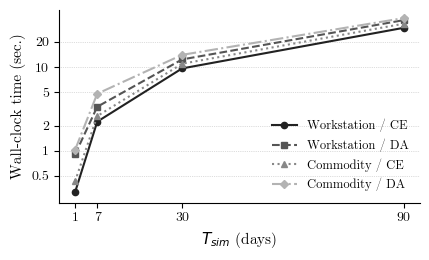

,T_sim (days),Hardware,Mechanism,Peak Memory (MB),Events (avg),Trace size (MB)
0,1,Workstation,CE,35.73,3320,0.11
1,1,Workstation,DA,37.5,3213,0.18
2,1,Commodity,CE,37.86,3320,0.11
3,1,Commodity,DA,39.48,3213,0.18
4,7,Workstation,CE,39.61,23889,0.81
5,7,Workstation,DA,43.0,23234,1.27
6,7,Commodity,CE,41.92,23889,0.81
7,7,Commodity,DA,45.83,23234,1.27
8,30,Workstation,CE,54.64,102741,3.56
9,30,Workstation,DA,63.19,99974,5.5


In [2]:
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd

try:
    _IN_IPYTHON = get_ipython() is not None
except NameError:
    _IN_IPYTHON = False

if not _IN_IPYTHON:
    import matplotlib
    matplotlib.use('Agg')

import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    def display(*args, **kwargs):
        return None

RESULTS_ROOT_OVERRIDE = None
SAVE_FIGURES = True
FIGURE_DIR_NAME = 'paper_figures'

plt.rcParams.update({
    'font.family': 'CMU Serif',
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'axes.unicode_minus': False,
})

SINGLE_FIGSIZE = (3.0, 2.0)
WIDE_FIGSIZE = (6.4, 2.2)
MULTIPANEL_FIGSIZE = (6.4, 4.2)
COORD_ORDER = ['FD', 'SD', 'CE', 'DA']
COORD_COLORS = {'FD': '#666666', 'SD': '#999999', 'CE': '#b3b3b3', 'DA': '#ffffff'}
COORD_HATCHES = {'FD': '', 'SD': '', 'CE': '', 'DA': 'ooo'}
EDGE_COLOR = '#222222'
GRID_COLOR = '#bdbdbd'
LINE_COLORS = ['#222222', '#555555', '#888888', '#b3b3b3', '#d0d0d0']
LINE_STYLES = ['-', '--', ':', '-.']
MARKERS = ['o', 's', '^', 'D', 'v']


def result_root_candidates():
    cwd = Path.cwd()
    candidates = []
    if RESULTS_ROOT_OVERRIDE is not None:
        candidates.append(Path(RESULTS_ROOT_OVERRIDE))
    candidates.extend([
        cwd,
        cwd / 'Paper Results',
        cwd.parent / 'Paper Results',
        Path.home() / 'Desktop' / 'COORDINATE-2.0' / 'Paper Results',
        Path.home() / 'Desktop' / 'Paper Results',
    ])
    unique = []
    for candidate in candidates:
        candidate = candidate.expanduser().resolve()
        if candidate not in unique:
            unique.append(candidate)
    return unique


def find_results_root(required_any=(), required_all=()):
    checked = []
    for root in result_root_candidates():
        checked.append(root)
        if not root.exists():
            continue
        has_any = True if not required_any else any((root / path).exists() for path in required_any)
        has_all = all((root / path).exists() for path in required_all)
        if has_any and has_all:
            return root
    raise FileNotFoundError('Could not find result files. Checked: ' + ', '.join(str(path) for path in checked))


def style_axes(ax, grid_axis='y'):
    ax.set_axisbelow(True)
    if grid_axis:
        ax.grid(axis=grid_axis, linestyle=':', linewidth=0.5, color=GRID_COLOR)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


def coord_color(label):
    return COORD_COLORS.get(str(label), '#b3b3b3')


def coord_hatch(label):
    return COORD_HATCHES.get(str(label), '')


def apply_hatches(bars, labels):
    for bar, label in zip(bars, labels):
        label = str(label)
        bar.set_facecolor(coord_color(label))
        bar.set_edgecolor(EDGE_COLOR)
        bar.set_linewidth(0.5)
        bar.set_hatch(coord_hatch(label))


def plot_coord_bars(ax, labels, values, width=0.72):
    labels = [str(label) for label in labels]
    x = np.arange(len(labels))
    bars = ax.bar(x, values, width=width)
    apply_hatches(bars, labels)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    style_axes(ax, grid_axis='y')
    return bars


def style_pandas_bar_containers(ax, labels):
    for container, label in zip(ax.containers, labels):
        for patch in container.patches:
            patch.set_facecolor(coord_color(label))
            patch.set_edgecolor(EDGE_COLOR)
            patch.set_linewidth(0.5)
            patch.set_hatch(coord_hatch(label))
    style_axes(ax, grid_axis='y')


def save_or_show(fig, root, filename=None):
    if SAVE_FIGURES and filename:
        out_dir = root / FIGURE_DIR_NAME
        out_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(out_dir / filename, bbox_inches='tight')
    if _IN_IPYTHON:
        plt.show()
    else:
        plt.close(fig)

ROOT = find_results_root(required_all=[Path('RQ4/runs.csv')])
rq4 = ROOT / 'RQ4'
runs_path = rq4 / 'runs.csv'

runs = pd.read_csv(runs_path)
if 'status' in runs.columns:
    runs = runs[runs['status'].fillna('ok') == 'ok'].copy()
else:
    runs = runs.copy()

required_cols = {'coord_label', 'sim_days', 'item_spawning_time', 'n_robots', 'rep'}
missing_cols = sorted(required_cols - set(runs.columns))
if missing_cols:
    raise ValueError(f'RQ4 runs.csv is missing required columns: {missing_cols}')

numeric_cols = [
    'sim_days', 'item_spawning_time', 'n_robots', 'rep', 'wall_time_s', 'event_count',
    'events_per_wall_s', 'max_rss_mb', 'trace_size_mb', 'overhead_trace_size_mb',
    'total_output_size_mb',
]
for col in numeric_cols:
    if col in runs.columns:
        runs[col] = pd.to_numeric(runs[col], errors='coerce')

runs['coord_label'] = runs['coord_label'].astype(str).str.upper().str.strip()
runs = runs[runs['coord_label'].isin(['CE', 'DA'])].copy()
if 'machine_label' in runs.columns:
    raw_machine = runs['machine_label']
else:
    raw_machine = pd.Series('', index=runs.index)
runs['machine_label'] = raw_machine.fillna('').astype(str).str.lower().str.strip()


def hardware_profile(label):
    if label in {'', 'nan', 'none', 'null', 'workstation', 'ws'}:
        return 'Workstation HW'
    if label in {'mac', 'commodity', 'commodity-hardware', 'commodity_hw'}:
        return 'Commodity HW'
    return label.replace('_', ' ').replace('-', ' ').title()

runs['hardware'] = runs['machine_label'].map(hardware_profile)
runs['profile'] = runs['hardware'] + ' / ' + runs['coord_label']
hardware_order = ['Workstation HW', 'Commodity HW']
coord_order = ['CE', 'DA']
profile_order = [f'{hardware} / {coord}' for hardware, coord in product(hardware_order, coord_order)]
profile_labels = {
    'Workstation HW / CE': 'Workstation / CE',
    'Workstation HW / DA': 'Workstation / DA',
    'Commodity HW / CE': 'Commodity / CE',
    'Commodity HW / DA': 'Commodity / DA',
}

summary = (
    runs.groupby(['sim_days', 'hardware', 'coord_label', 'profile'], as_index=False)
    .agg(
        wall_time_s=('wall_time_s', 'mean'),
        event_count=('event_count', 'mean'),
        max_rss_mb=('max_rss_mb', 'mean'),
        total_output_size_mb=('total_output_size_mb', 'mean'),
        runs=('run_id', 'count'),
    )
)
summary['hardware'] = pd.Categorical(summary['hardware'], categories=hardware_order, ordered=True)
summary['coord_label'] = pd.Categorical(summary['coord_label'], categories=coord_order, ordered=True)
summary['profile'] = pd.Categorical(summary['profile'], categories=profile_order, ordered=True)
summary = summary.sort_values(['sim_days', 'hardware', 'coord_label'])

sim_days_order = sorted(summary['sim_days'].dropna().unique())
resource_index = pd.MultiIndex.from_product(
    [sim_days_order, hardware_order, coord_order],
    names=['sim_days', 'hardware', 'coord_label'],
)
resource_source = (
    summary.set_index(['sim_days', 'hardware', 'coord_label'])
    .reindex(resource_index)
    .reset_index()
)
resource_table = resource_source[[
    'sim_days', 'hardware', 'coord_label',
    'max_rss_mb', 'event_count', 'total_output_size_mb',
]].rename(columns={
    'sim_days': 'T_sim (days)',
    'hardware': 'Hardware',
    'coord_label': 'Mechanism',
    'max_rss_mb': 'Peak Memory (MB)',
    'event_count': 'Events (avg)',
    'total_output_size_mb': 'Trace size (MB)',
})
resource_table['Hardware'] = resource_table['Hardware'].str.replace(' HW', '', regex=False)
resource_table['Peak Memory (MB)'] = resource_table['Peak Memory (MB)'].round(2)
resource_table['Events (avg)'] = resource_table['Events (avg)'].round(0).astype('Int64')
resource_table['Trace size (MB)'] = resource_table['Trace size (MB)'].round(2)

series = {profile: summary[summary['profile'] == profile].set_index('sim_days') for profile in profile_order}
profile_line_styles = {
    'Workstation HW / CE': '-',
    'Workstation HW / DA': '-',
    'Commodity HW / CE': '--',
    'Commodity HW / DA': ':',
}
fig, ax = plt.subplots(1, 1, figsize=(4.4, 2.7))
for idx, profile in enumerate(profile_order):
    frame = series.get(profile)
    if frame is None or frame.empty:
        continue
    values = frame['wall_time_s'].reindex(sim_days_order)
    ax.plot(
        sim_days_order,
        values,
        label=profile_labels.get(profile, profile),
        color=LINE_COLORS[idx % len(LINE_COLORS)],
        linestyle=profile_line_styles.get(profile, LINE_STYLES[idx % len(LINE_STYLES)]),
        marker=MARKERS[idx % len(MARKERS)],
        linewidth=1.5,
        markersize=4.5,
    )
ax.set_xlabel('$T_{sim}$ (days)', fontsize=11)
ax.set_ylabel('Wall-clock time (sec.)', fontsize=11)
ax.set_yscale('log')
wall_values = summary['wall_time_s'].dropna()
if not wall_values.empty:
    y_min = max(0.1, wall_values.min() * 0.75)
    y_max = wall_values.max() * 1.25
    tick_candidates = np.array([0.2, 0.5, 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000])
    y_ticks = tick_candidates[(tick_candidates >= y_min) & (tick_candidates <= y_max)]
    ax.set_ylim(y_min, y_max)
    ax.set_yticks(y_ticks)
    ax.set_yticklabels([f'{tick:g}' for tick in y_ticks])
    ax.minorticks_off()
ax.set_xticks(sim_days_order)
ax.tick_params(axis='both', labelsize=10)
style_axes(ax, grid_axis='y')
ax.legend(loc='lower right', frameon=False, fontsize=9)
fig.tight_layout()
save_or_show(fig, ROOT, 'rq4_wall_time_scalability.pdf')
resource_table_display = resource_table.astype(object).where(resource_table.notna(), '--')
display(resource_table_display)